# Ibupreneur Academy: Data Understanding & Exploratory Data Analysis

**Research:** Predicting Performance Trajectories of Women Micro-Enterprises: An Early Warning Framework  



In [2]:
# 0. SETUP — CONNECT GOOGLE DRIVE & PROJECT FOLDER

from google.colab import drive
from pathlib import Path

# Mount Google Drive
drive.mount('/content/drive')

# Main research folder
PROJECT_DIR = Path(
    "/content/drive/MyDrive/24088950_MAI_Research"
)

# Raw dataset
DATA_PATH = PROJECT_DIR / (
    "Ibupreneur_Academy_Microenterprise_Performance_Raw_Dataset_2025_2026.xlsm"
)

# Check connection
print("Project folder:", PROJECT_DIR)
print("Dataset:", DATA_PATH)
print("Project folder exists:", PROJECT_DIR.exists())
print("Dataset exists:", DATA_PATH.exists())

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found:\n{DATA_PATH}\n"
        "Please check the filename and location in Google Drive."
    )

Mounted at /content/drive
Project folder: /content/drive/MyDrive/24088950_MAI_Research
Dataset: /content/drive/MyDrive/24088950_MAI_Research/Ibupreneur_Academy_Microenterprise_Performance_Raw_Dataset_2025_2026.xlsm
Project folder exists: True
Dataset exists: True


In [3]:
import pandas as pd

excel_file = pd.ExcelFile(DATA_PATH)

print("Available sheets:")
print(excel_file.sheet_names)

Available sheets:
['README', 'Demographics', 'Pre-Post Module', 'Finance Sales Profit', 'Social Media', 'SSM', 'Attendance Modules', 'Dropout Attrition', 'Behavior Points']


## 1. Load the research workbook

In [4]:
# 1. Load sheets

dem = pd.read_excel(DATA_PATH, sheet_name="Demographics", header=3)
prepost = pd.read_excel(DATA_PATH, sheet_name="Pre-Post Module", header=3)
finance = pd.read_excel(DATA_PATH, sheet_name="Finance Sales Profit", header=3)
ssm = pd.read_excel(DATA_PATH, sheet_name="SSM", header=3)
attendance = pd.read_excel(DATA_PATH, sheet_name="Attendance Modules", header=3)
dropout = pd.read_excel(DATA_PATH, sheet_name="Dropout Attrition", header=3)
behavior = pd.read_excel(DATA_PATH, sheet_name="Behavior Points", header=3)

# Social Media has the actual field names on Excel row 5.
social = pd.read_excel(DATA_PATH, sheet_name="Social Media", header=4)
social = social.iloc[:, :17].copy()
social.columns = [
    "Cohort ID", "Funder/Program", "Year", "Participant ID",
    "Full Name [REMOVED - PII]",
    "IG_has_pre", "IG_followers_pre",
    "FB_has_pre", "FB_followers_pre",
    "TT_has_pre", "TT_followers_pre",
    "IG_has_post", "IG_followers_post",
    "FB_has_post", "FB_followers_post",
    "TT_has_post", "TT_followers_post",
]

# Keep participant rows only.
dem = dem[dem["Participant ID"].notna()].copy()
prepost = prepost[prepost["Participant ID"].notna()].copy()
finance = finance[finance["Participant ID"].notna()].copy()
social = social[social["Participant ID"].notna()].copy()
ssm = ssm[ssm["Participant ID"].notna()].copy()
attendance = attendance[attendance["Participant ID"].notna()].copy()
dropout = dropout[dropout["Participant ID"].notna()].copy()
behavior = behavior[behavior["Participant ID"].notna()].copy()

# Normalize status spelling without changing the source column.
dem["Status_clean"] = (
    dem["Status"].astype("string").str.strip().str.upper()
    .replace({"DROP OUT": "DROPOUT"})
)

# Age must be a numeric value in the research analysis.
dem["Age"] = pd.to_numeric(dem["Age"], errors="coerce")

print("Loaded successfully.")

Loaded successfully.


## 2. Dataset inventory and participant coverage

In [5]:
# 2.1 Workbook-level participant coverage

sheet_map = {
    "Demographics": dem,
    "Pre-Post Module": prepost,
    "Finance Sales Profit": finance,
    "Social Media": social,
    "SSM": ssm,
    "Attendance Modules": attendance,
    "Behavior Points": behavior,
    "Dropout Attrition": dropout,
}

inventory = []
for name, df in sheet_map.items():
    inventory.append({
        "Sheet": name,
        "Rows": len(df),
        "Unique Participants": df["Participant ID"].nunique(),
        "Columns": df.shape[1],
    })

inventory = pd.DataFrame(inventory)
display(inventory)

cohort_counts = (
    dem.groupby(["Cohort ID", "Funder/Program", "Year"], dropna=False)
       ["Participant ID"].nunique()
       .reset_index(name="Participants")
       .sort_values(["Year", "Cohort ID"])
)
display(cohort_counts)

print("Unique participants in Demographics:", dem["Participant ID"].nunique())
print("Number of cohorts:", dem["Cohort ID"].nunique())

,Sheet,Rows,Unique Participants,Columns
0,Demographics,201,201,41
1,Pre-Post Module,198,198,149
2,Finance Sales Profit,196,196,24
3,Social Media,199,199,17
4,SSM,206,206,8
5,Attendance Modules,199,198,67
6,Behavior Points,1902,201,16
7,Dropout Attrition,12,12,19


,Cohort ID,Funder/Program,Year,Participants
2,MBSB-2025-C1,MBSB,2025,20
3,MIB-2025-C1,MIB,2025,33
4,MIB-2025-C2,MIB,2025,34
5,MIB-2025-C3,MIB,2025,28
0,AIB-2026-MEKAR-C1,AIB,2026,30
1,CIMB-2026-MH-C1,CIMB,2026,31
6,UNDP-2026-C1,UNDP,2026,25


Unique participants in Demographics: 201
Number of cohorts: 7


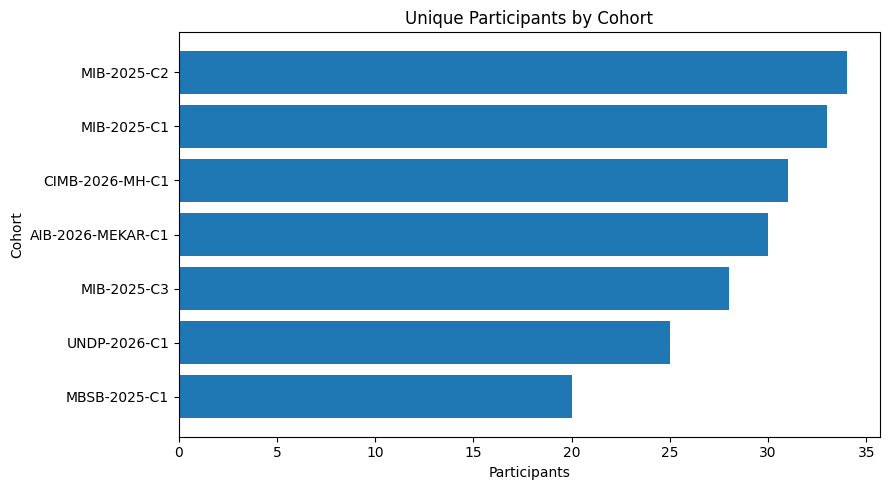

In [6]:
import matplotlib.pyplot as plt

# 2.2 Visual: participant count by cohort

plot_df = cohort_counts.sort_values("Participants")
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(plot_df["Cohort ID"], plot_df["Participants"])
ax.set_title("Unique Participants by Cohort")
ax.set_xlabel("Participants")
ax.set_ylabel("Cohort")
plt.tight_layout()
plt.show()

## 3. Privacy and de-identification audit

The analysis should contain only pseudonymous Participant IDs and research-relevant variables. Columns explicitly labelled `[REMOVED ...]` should be blank.

In [7]:
# 3.1 Audit all columns marked REMOVED

privacy_rows = []
for sheet_name, df in sheet_map.items():
    removed_cols = [c for c in df.columns if "REMOVED" in str(c)]
    for c in removed_cols:
        nonblank = (
            df[c].notna()
            & df[c].astype("string").str.strip().ne("")
        ).sum()
        privacy_rows.append({
            "Sheet": sheet_name,
            "Column": c,
            "Nonblank Values": int(nonblank),
        })

privacy_audit = pd.DataFrame(privacy_rows)
display(privacy_audit)

if len(privacy_audit):
    print("Any residual values in explicitly removed fields:",
          bool((privacy_audit["Nonblank Values"] > 0).any()))

,Sheet,Column,Nonblank Values
0,Demographics,Full Name [REMOVED - PII],0
1,Demographics,IC Number [REMOVED - PII],0
2,Demographics,SSM Name [REMOVED - PII],0
3,Demographics,SSM Number [REMOVED - PII],0
4,Demographics,Instagram Handle [REMOVED - PII],0
5,Demographics,Facebook Handle [REMOVED - PII],0
6,Demographics,TikTok Handle [REMOVED - PII],0
7,Demographics,Additional Remarks [REMOVED - sensitive free t...,0
8,Pre-Post Module,Full Name [REMOVED - PII],0
9,Finance Sales Profit,Full Name [REMOVED - PII],0


Any residual values in explicitly removed fields: False


### Privacy interpretation
`Participant ID` is retained because it is required to link sheets. It should be treated as a **pseudonymous research key**, not as public data. The final modelling dataset should not include names, IC, contact numbers, social-media handles, SSM identifiers, banking details, or sensitive free-text remarks.

## 4. Participant-ID integrity and cross-sheet linkage audit

In [8]:
# 4.1 Duplicate participant IDs / repeated record audit

duplicate_audit = []

for sheet_name, df in sheet_map.items():

    # Behavior Points is intentionally long format:
    # one participant can appear multiple times across different modules/sessions.
    if sheet_name == "Behavior Points":

        # Only flag if the SAME participant has the SAME module/session more than once
        counts = (
            df.groupby(["Participant ID", "Module / Session"])
              .size()
              .reset_index(name="Rows")
        )

        dups = counts[counts["Rows"] > 1]

        for _, row in dups.iterrows():
            duplicate_audit.append({
                "Sheet": sheet_name,
                "Participant ID": row["Participant ID"],
                "Module / Session": row["Module / Session"],
                "Rows": int(row["Rows"]),
                "Issue": "Same participant + same module repeated"
            })

    else:
        # Other sheets are expected to have one row per participant
        counts = df["Participant ID"].value_counts()
        dups = counts[counts > 1]

        for pid, n in dups.items():
            duplicate_audit.append({
                "Sheet": sheet_name,
                "Participant ID": pid,
                "Module / Session": None,
                "Rows": int(n),
                "Issue": "Participant ID repeated"
            })

duplicate_audit = pd.DataFrame(duplicate_audit)

if len(duplicate_audit) == 0:
    display(pd.DataFrame({
        "Result": ["No unexpected duplicate records detected"]
    }))
else:
    display(duplicate_audit)

,Sheet,Participant ID,Module / Session,Rows,Issue
0,Attendance Modules,2025_IBU-ACADEMY-MIB-C2-15,None,2,Participant ID repeated


In [9]:
# 4.2 Linkage against the Demographics participant spine

dem_ids = set(dem["Participant ID"])

linkage = []
for sheet_name, df in sheet_map.items():
    if sheet_name in {"Demographics", "Dropout Attrition"}:
        continue
    ids = set(df["Participant ID"].dropna())
    linkage.append({
        "Sheet": sheet_name,
        "Unique IDs": len(ids),
        "IDs not in Demographics": len(ids - dem_ids),
        "Demographics IDs missing from sheet": len(dem_ids - ids),
    })

linkage = pd.DataFrame(linkage)
display(linkage)

# List exact mismatches for manual checking.
ssm_extra_ids = sorted(set(ssm["Participant ID"]) - dem_ids)
print("SSM IDs not currently in Demographics:", ssm_extra_ids)

,Sheet,Unique IDs,IDs not in Demographics,Demographics IDs missing from sheet
0,Pre-Post Module,198,0,3
1,Finance Sales Profit,196,0,5
2,Social Media,199,0,2
3,SSM,206,5,0
4,Attendance Modules,198,0,3
5,Behavior Points,201,0,0


SSM IDs not currently in Demographics: ['2025_IBU-ACADEMY-MIB-C1-24', '2026_IA-JHR-C1-05', '2026_IA-JHR-C1-12', '2026_IA-JHR-C1-19', '2026_IA-JHR-C1-22']


### Initial linkage flags to resolve
The current workbook snapshot contains two items worth manual checking before modelling:

1. `Attendance Modules` contains a duplicate record for Participant ID `2025_IBU-ACADEMY-MIB-C2-15`.
2. `SSM` currently contains several IDs that do not appear in the Demographics participant spine.


## 5. Missingness and structural N/A

In [10]:
# 5.1 General demographic missingness

dem_core = [
    "State", "Age", "Marital Status", "Education Level", "Working Status",
    "Industry/Business Sector", "Years in Business", "Household Income",
    "Total Commitment", "Estimated Remaining Balance"
]

dem_missing = pd.DataFrame({
    "Variable": dem_core,
    "Missing n": [dem[c].isna().sum() for c in dem_core],
    "Missing %": [dem[c].isna().mean() * 100 for c in dem_core],
})
display(dem_missing.sort_values("Missing %", ascending=False))

,Variable,Missing n,Missing %
6,Years in Business,21,10.447761
0,State,19,9.452736
1,Age,0,0.000000
2,Marital Status,0,0.000000
4,Working Status,0,0.000000
3,Education Level,0,0.000000
5,Industry/Business Sector,0,0.000000
7,Household Income,0,0.000000
8,Total Commitment,0,0.000000
9,Estimated Remaining Balance,0,0.000000


In [11]:
# 5.2 Pre/Post: distinguish true missing from structural N/A

pp_feature_cols = [
    c for c in prepost.columns
    if c not in ["Cohort ID", "Funder/Program", "Year", "Participant ID",
                 "Full Name [REMOVED - PII]"]
]

pp_quality = []
for c in pp_feature_cols:
    s = prepost[c]
    structural_na = s.astype("string").str.strip().str.upper().eq("N/A")
    true_missing = s.isna() | s.astype("string").str.strip().eq("")
    pp_quality.append({
        "Variable": c,
        "Structural N/A %": structural_na.mean() * 100,
        "True Missing %": true_missing.mean() * 100,
        "Observed %": (~structural_na & ~true_missing).mean() * 100,
    })

pp_quality = pd.DataFrame(pp_quality)
display(pp_quality.sort_values("Structural N/A %", ascending=False).head(25))

,Variable,Structural N/A %,True Missing %,Observed %
0,Pre - Able to identify 3 personal strengths a...,0.0,36.868687,63.131313
1,Post - Able to identify 3 personal strengths ...,0.0,36.868687,63.131313
2,Pre - Have vision board,0.0,51.010101,48.989899
3,Post - Have vision board,0.0,51.010101,48.989899
4,Pre- Your product label — does it include the ...,0.0,68.686869,31.313131
5,Post - Your product label — does it include th...,0.0,68.686869,31.313131
6,Pre - Have a Standard Operating Procedure (SOP...,0.0,53.535354,46.464646
7,Post - Have a Standard Operating Procedure (SO...,0.0,54.545455,45.454545
8,Pre - Aware actual cost and selling price,0.0,26.767677,73.232323
9,Post - Aware actual cost and selling price,0.0,29.292929,70.707071


**Rule for later preprocessing:** structural `N/A` means the item/module was not applicable or not run for that cohort. It must **not** be converted to `0` or treated as a negative response.

## 6. Demographic and cohort comparability EDA

In [12]:
# 6.1 Descriptive statistics

numeric_demo = ["Age", "Years in Business", "Household Income",
                "Total Commitment", "Estimated Remaining Balance"]

for c in numeric_demo:
    dem[c] = pd.to_numeric(dem[c], errors="coerce")

display(dem[numeric_demo].describe().T)

cohort_demo = (
    dem.groupby("Cohort ID")
       .agg(
           participants=("Participant ID", "nunique"),
           age_median=("Age", "median"),
           age_mean=("Age", "mean"),
           years_business_median=("Years in Business", "median"),
           household_income_median=("Household Income", "median"),
       )
       .reset_index()
)
display(cohort_demo)

,count,mean,std,min,25%,50%,75%,max
Age,201.0,28.407960,6.398651,26.00,26.0,26.0,26.0,54.0
Years in Business,180.0,6.178889,5.352950,0.00,3.0,5.0,10.0,40.0
Household Income,181.0,2443.554309,1255.796529,0.00,1500.0,2300.0,3000.0,7500.0
Total Commitment,181.0,3287.283536,1305.453013,1069.00,2391.0,3160.0,3980.0,7907.0
Estimated Remaining Balance,181.0,-446.459466,859.961101,-3377.95,-1000.0,-340.0,194.0,1340.0


,Cohort ID,participants,age_median,age_mean,years_business_median,household_income_median
0,AIB-2026-MEKAR-C1,30,26.0,26.000000,5.5,2000.0
1,CIMB-2026-MH-C1,31,40.0,41.612903,5.0,2500.0
2,MBSB-2025-C1,20,26.0,26.000000,3.5,2500.0
3,MIB-2025-C1,33,26.0,26.000000,3.0,2800.0
4,MIB-2025-C2,34,26.0,26.000000,5.0,1950.0
5,MIB-2025-C3,28,26.0,26.000000,4.0,3000.0
6,UNDP-2026-C1,25,26.0,26.000000,6.0,1800.0


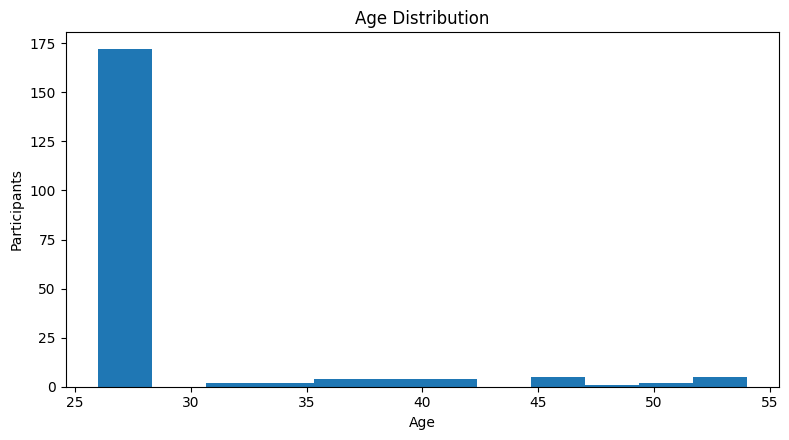

In [13]:
# 6.2 Age distribution

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(dem["Age"].dropna(), bins=12)
ax.set_title("Age Distribution")
ax.set_xlabel("Age")
ax.set_ylabel("Participants")
plt.tight_layout()
plt.show()

## 7. Behavior Points EDA

The participant journal and project-delivery Point System show that behavior points are awarded throughout classes for behaviors such as journal use/reflection, homework completion, early attendance, check-in/check-out, social-media posting, and trainer bonuses. Participants generally start from **50 points**, and extra points can push the final score above 100.

Because cohorts have different numbers of modules/sessions, **raw final points should not be compared across cohorts without adjustment**. For cross-cohort analysis, this notebook derives:
- total gain and deduction,
- average gain/deduction per session,
- net behavior points,
- session count,
- final behavior points,
- within-cohort percentile,
- within-cohort z-score.

The original final score/grade is retained; derived normalized metrics are added without overwriting the source.

In [14]:
import numpy as np
# 7.1 Clean behavior fields

behavior_numeric = [
    "Module Order", "Start Point", "Gain", "Deduct",
    "Net Behavior Point", "Running Total",
    "Final Behavior Points", "Final Behavior Score %"
]
for c in behavior_numeric:
    behavior[c] = pd.to_numeric(behavior[c], errors="coerce")

def last_non_null(series):
    s = series.dropna()
    if len(s) == 0:
        return np.nan
    return s.iloc[-1]

behavior_summary = (
    behavior.sort_values(["Participant ID", "Module Order"])
            .groupby(["Participant ID", "Cohort ID", "Funder/Program", "Year"],
                     as_index=False)
            .agg(
                behavior_sessions=("Module / Session", "count"),
                behavior_total_gain=("Gain", "sum"),
                behavior_total_deduct=("Deduct", "sum"),
                behavior_net_total=("Net Behavior Point", "sum"),
                behavior_avg_gain_per_session=("Gain", "mean"),
                behavior_avg_deduct_per_session=("Deduct", "mean"),
                behavior_net_std=("Net Behavior Point", "std"),
                behavior_final_points=("Final Behavior Points", last_non_null),
                behavior_source_grade=("Grade", last_non_null),
                behavior_source_performance=("Behavior Performance", last_non_null),
            )
)

# Cross-cohort normalization to reduce confounding from different module counts.
behavior_summary["behavior_final_percentile_in_cohort"] = (
    behavior_summary.groupby("Cohort ID")["behavior_final_points"]
                    .rank(pct=True, method="average")
)

def within_group_z(s):
    sd = s.std(ddof=0)
    if pd.isna(sd) or sd == 0:
        return pd.Series(np.zeros(len(s)), index=s.index)
    return (s - s.mean()) / sd

behavior_summary["behavior_final_z_in_cohort"] = (
    behavior_summary.groupby("Cohort ID")["behavior_final_points"]
                    .transform(within_group_z)
)

# Derived grade for analysis only; does NOT replace the source grade.
# The source rubric uses: A 80-100, B 60-79, C 40-59, D 20-39, F <20.
# Source sheets also assign A to bonus-point scores >100, so >=80 is treated as A.
def derive_behavior_grade(x):
    if pd.isna(x):
        return np.nan
    if x >= 80:
        return "A"
    if x >= 60:
        return "B"
    if x >= 40:
        return "C"
    if x >= 20:
        return "D"
    return "F"

behavior_summary["behavior_grade_derived"] = (
    behavior_summary["behavior_final_points"].apply(derive_behavior_grade)
)

display(behavior_summary.head())
print("Behavior participants:", behavior_summary["Participant ID"].nunique())

,Participant ID,Cohort ID,Funder/Program,Year,behavior_sessions,behavior_total_gain,behavior_total_deduct,behavior_net_total,behavior_avg_gain_per_session,behavior_avg_deduct_per_session,behavior_net_std,behavior_final_points,behavior_source_grade,behavior_source_performance,behavior_final_percentile_in_cohort,behavior_final_z_in_cohort,behavior_grade_derived
0,2025_IBU-ACADEMY-MBSB-C1-02,MBSB-2025-C1,MBSB,2025,8,44.0,0.0,44.0,5.500,NaN,4.140393,94.0,A,NaN,0.425,-0.354240,A
1,2025_IBU-ACADEMY-MBSB-C1-03,MBSB-2025-C1,MBSB,2025,8,45.0,15.0,30.0,5.625,15.0,8.048957,80.0,A,NaN,0.050,-1.823682,A
2,2025_IBU-ACADEMY-MBSB-C1-04,MBSB-2025-C1,MBSB,2025,8,59.0,0.0,59.0,7.375,NaN,3.113909,109.0,A,NaN,0.900,1.220161,A
3,2025_IBU-ACADEMY-MBSB-C1-05,MBSB-2025-C1,MBSB,2025,8,59.0,0.0,59.0,7.375,NaN,3.113909,109.0,A,NaN,0.900,1.220161,A
4,2025_IBU-ACADEMY-MBSB-C1-06,MBSB-2025-C1,MBSB,2025,8,61.0,0.0,61.0,7.625,NaN,3.248626,111.0,A,NaN,1.000,1.430082,A


Behavior participants: 201


In [15]:
# 7.2 Behavior coverage and descriptive statistics by cohort

behavior_cohort = (
    behavior_summary.groupby("Cohort ID")
    .agg(
        participants=("Participant ID", "nunique"),
        sessions_per_participant_median=("behavior_sessions", "median"),
        final_points_mean=("behavior_final_points", "mean"),
        final_points_median=("behavior_final_points", "median"),
        final_points_min=("behavior_final_points", "min"),
        final_points_max=("behavior_final_points", "max"),
        total_deduct_median=("behavior_total_deduct", "median"),
    )
    .reset_index()
)
display(behavior_cohort)

print("Participants with final behavior points >100:",
      (behavior_summary["behavior_final_points"] > 100).sum())
print("Participants with final behavior points <0:",
      (behavior_summary["behavior_final_points"] < 0).sum())

,Cohort ID,participants,sessions_per_participant_median,final_points_mean,final_points_median,final_points_min,final_points_max,total_deduct_median
0,AIB-2026-MEKAR-C1,30,9.0,95.166667,104.5,8.0,109.0,0.0
1,CIMB-2026-MH-C1,31,11.0,103.806452,111.0,57.5,115.0,0.0
2,MBSB-2025-C1,20,8.0,97.375000,97.5,80.0,111.0,0.0
3,MIB-2025-C1,33,7.0,104.636364,106.0,85.0,110.0,0.0
4,MIB-2025-C2,34,13.0,95.852941,106.5,-13.0,112.0,0.0
5,MIB-2025-C3,28,11.0,100.464286,104.0,80.0,109.0,0.0
6,UNDP-2026-C1,25,6.0,97.960000,102.0,78.0,104.0,0.0


Participants with final behavior points >100: 133
Participants with final behavior points <0: 1


In [16]:
# 7.2 Behavior coverage and descriptive statistics by cohort

behavior_cohort = (
    behavior_summary.groupby("Cohort ID")
    .agg(
        participants=("Participant ID", "nunique"),
        sessions_per_participant_median=("behavior_sessions", "median"),
        final_points_mean=("behavior_final_points", "mean"),
        final_points_median=("behavior_final_points", "median"),
        final_points_min=("behavior_final_points", "min"),
        final_points_max=("behavior_final_points", "max"),
        total_deduct_median=("behavior_total_deduct", "median"),
    )
    .reset_index()
)
display(behavior_cohort)

print("Participants with final behavior points >100:",
      (behavior_summary["behavior_final_points"] > 100).sum())
print("Participants with final behavior points <0:",
      (behavior_summary["behavior_final_points"] < 0).sum())

,Cohort ID,participants,sessions_per_participant_median,final_points_mean,final_points_median,final_points_min,final_points_max,total_deduct_median
0,AIB-2026-MEKAR-C1,30,9.0,95.166667,104.5,8.0,109.0,0.0
1,CIMB-2026-MH-C1,31,11.0,103.806452,111.0,57.5,115.0,0.0
2,MBSB-2025-C1,20,8.0,97.375000,97.5,80.0,111.0,0.0
3,MIB-2025-C1,33,7.0,104.636364,106.0,85.0,110.0,0.0
4,MIB-2025-C2,34,13.0,95.852941,106.5,-13.0,112.0,0.0
5,MIB-2025-C3,28,11.0,100.464286,104.0,80.0,109.0,0.0
6,UNDP-2026-C1,25,6.0,97.960000,102.0,78.0,104.0,0.0


Participants with final behavior points >100: 133
Participants with final behavior points <0: 1


/tmp/ipykernel_1117/3442885036.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=cohorts, showfliers=True)


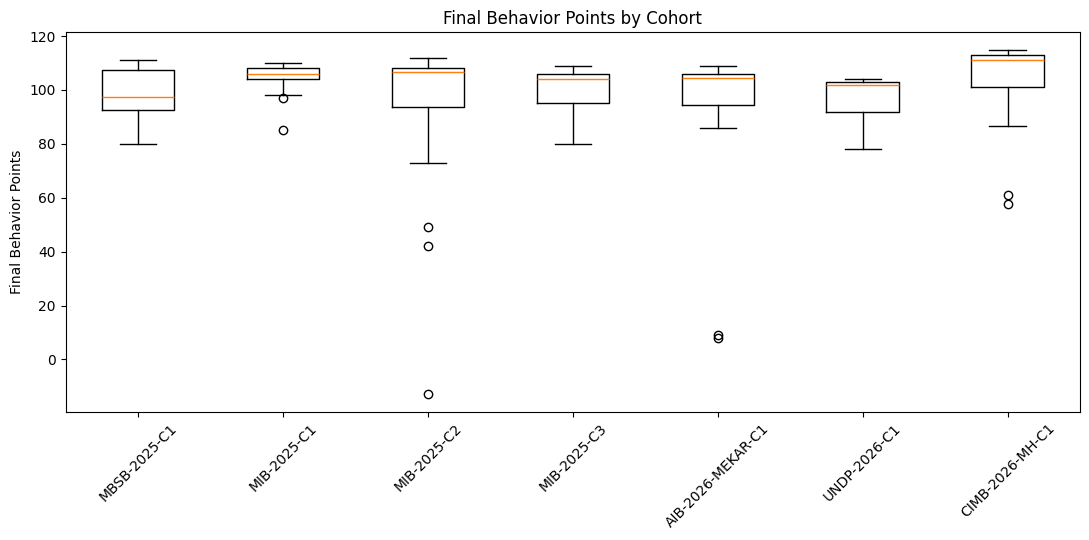

In [17]:
# 7.3 Behavior final points by cohort

cohorts = behavior_summary["Cohort ID"].dropna().unique()
data = [
    behavior_summary.loc[
        behavior_summary["Cohort ID"].eq(c), "behavior_final_points"
    ].dropna().values
    for c in cohorts
]

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.boxplot(data, labels=cohorts, showfliers=True)
ax.set_title("Final Behavior Points by Cohort")
ax.set_ylabel("Final Behavior Points")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

/tmp/ipykernel_1117/4259897313.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=cohorts, showfliers=True)


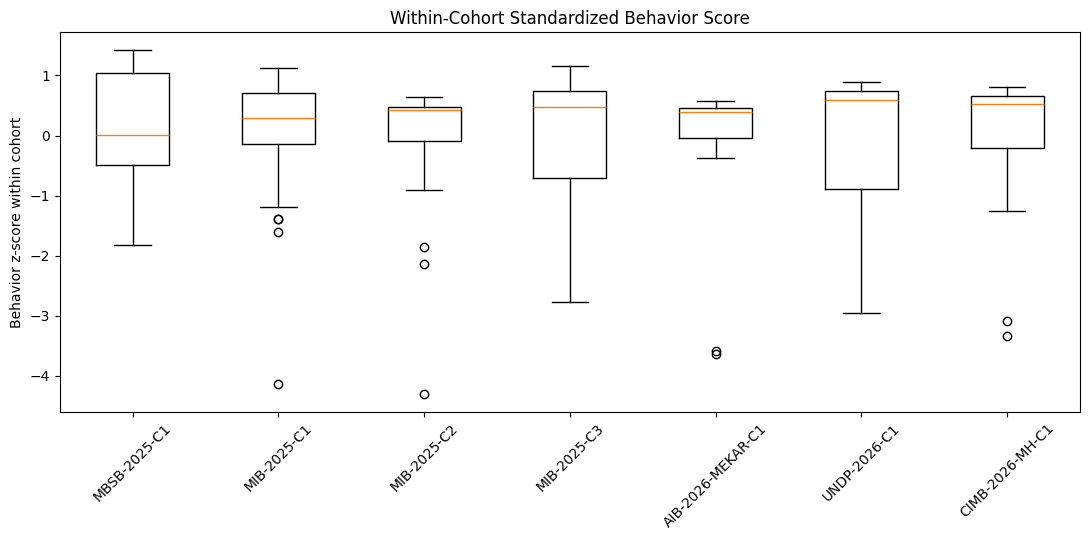

In [18]:
# 7.4 Normalized behavior score by cohort

fig, ax = plt.subplots(figsize=(11, 5.5))
data = [
    behavior_summary.loc[
        behavior_summary["Cohort ID"].eq(c),
        "behavior_final_z_in_cohort"
    ].dropna().values
    for c in cohorts
]
ax.boxplot(data, labels=cohorts, showfliers=True)
ax.set_title("Within-Cohort Standardized Behavior Score")
ax.set_ylabel("Behavior z-score within cohort")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

### Behavior-point modelling note
For the predictive model, consider using the **participant-level behavior aggregates** rather than every module row. The strongest cross-cohort candidates are likely:
- `behavior_avg_gain_per_session`
- `behavior_avg_deduct_per_session`
- `behavior_net_total`
- `behavior_final_percentile_in_cohort`
- `behavior_final_z_in_cohort`


## 8. Social-media completeness

In [19]:
import re
import numpy as np

# 8.1 Parse follower metrics such as "1K"

def parse_count(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip().upper().replace(",", "")
    if s in {"", "N/A", "NA", "NONE", "-", "NAN"}:
        return np.nan
    m = re.fullmatch(r"([0-9]*\.?[0-9]+)\s*([KM]?)\+?", s)
    if not m:
        return pd.to_numeric(s, errors="coerce")
    value = float(m.group(1))
    suffix = m.group(2)
    if suffix == "K":
        value *= 1_000
    elif suffix == "M":
        value *= 1_000_000
    return value

for c in [
    "IG_followers_pre", "FB_followers_pre", "TT_followers_pre",
    "IG_followers_post", "FB_followers_post", "TT_followers_post",
]:
    social[c] = social[c].map(parse_count)

social_completeness = pd.DataFrame({
    "Metric": [
        "IG followers baseline", "FB followers baseline", "TT followers baseline",
        "IG followers post", "FB followers post", "TT followers post",
    ],
    "Available n": [
        social["IG_followers_pre"].notna().sum(),
        social["FB_followers_pre"].notna().sum(),
        social["TT_followers_pre"].notna().sum(),
        social["IG_followers_post"].notna().sum(),
        social["FB_followers_post"].notna().sum(),
        social["TT_followers_post"].notna().sum(),
    ]
})
social_completeness["Available %"] = (
    social_completeness["Available n"] / social["Participant ID"].nunique() * 100
)
display(social_completeness)

,Metric,Available n,Available %
0,IG followers baseline,133,66.834171
1,FB followers baseline,140,70.351759
2,TT followers baseline,141,70.854271
3,IG followers post,47,23.618090
4,FB followers post,47,23.618090
5,TT followers post,44,22.110553


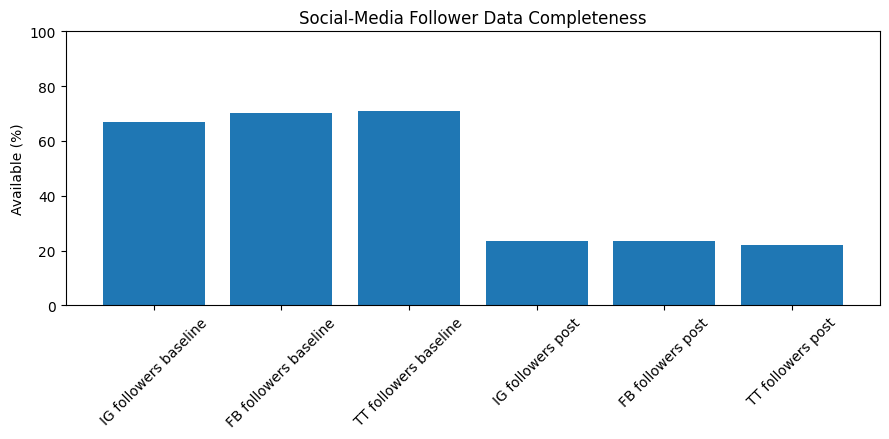

In [20]:
# 8.2 Visual completeness comparison

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(social_completeness["Metric"], social_completeness["Available %"])
ax.set_title("Social-Media Follower Data Completeness")
ax.set_ylabel("Available (%)")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

**Interpretation:** post-program follower counts should remain a secondary/descriptive variable unless follow-up coverage improves. Missing post-program followers should **not** be imputed merely to increase sample size.

## 9. Finance data and outcome-readiness audit

In [21]:
# 9.1 Clean finance values

def parse_rm_number(x):
    if pd.isna(x):
        return np.nan
    if isinstance(x, (int, float, np.number)):
        return float(x)
    s = str(x).strip().upper()
    if s in {"", "N/A", "NA", "-", "NONE", "NAN"}:
        return np.nan
    s = s.replace("RM", "").replace(",", "").replace("%", "").strip()
    return pd.to_numeric(s, errors="coerce")

finance_numeric = [
    "Months Tracked",
    "Sales Before Program", "Sales Month 1", "Sales Month 2", "Sales Month 3",
    "Total Sales Revenue", "Average Monthly Sales",
    "Profit Before Program", "Profit Month 1", "Profit Month 2", "Profit Month 3",
    "Total Profit", "Total Cost for 3 Months",
    "Total Seed Funding Received", "Total Bonus Payout"
]
for c in finance_numeric:
    if c in finance.columns:
        finance[c] = finance[c].map(parse_rm_number)

sales_cols = ["Sales Before Program", "Sales Month 1", "Sales Month 2", "Sales Month 3"]
finance["complete_S0_S3"] = finance[sales_cols].notna().all(axis=1)

finance_completeness = (
    finance.groupby("Cohort ID")
    .agg(
        participants=("Participant ID", "nunique"),
        complete_S0_S3=("complete_S0_S3", "sum"),
    )
    .reset_index()
)
finance_completeness["complete_S0_S3_%"] = (
    finance_completeness["complete_S0_S3"] /
    finance_completeness["participants"] * 100
)
display(finance_completeness)

,Cohort ID,participants,complete_S0_S3,complete_S0_S3_%
0,AIB-2026-MEKAR-C1,28,26,92.857143
1,CIMB-2026-MH-C1,28,25,89.285714
2,MBSB-2025-C1,20,18,90.000000
3,MIB-2025-C1,33,27,81.818182
4,MIB-2025-C2,34,30,88.235294
5,MIB-2025-C3,28,24,85.714286
6,UNDP-2026-C1,25,23,92.000000


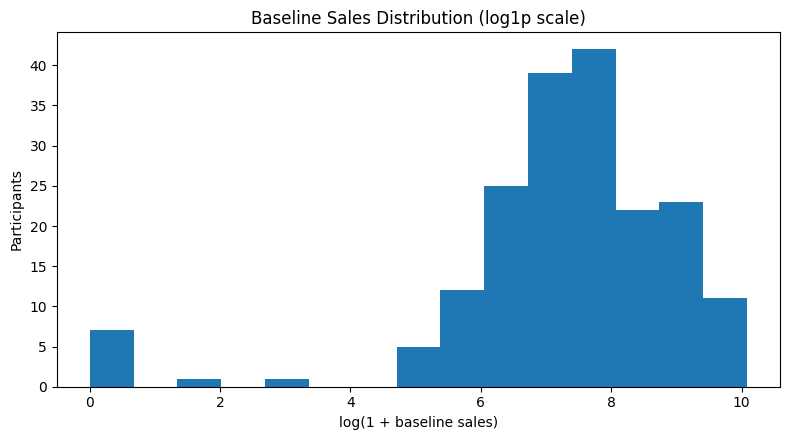

In [22]:
# 9.2 Baseline sales distribution

fig, ax = plt.subplots(figsize=(8, 4.5))
baseline_sales = finance["Sales Before Program"].dropna()
ax.hist(np.log1p(baseline_sales.clip(lower=0)), bins=15)
ax.set_title("Baseline Sales Distribution (log1p scale)")
ax.set_xlabel("log(1 + baseline sales)")
ax.set_ylabel("Participants")
plt.tight_layout()
plt.show()

## 10. Pre/Post module coverage

In [23]:
# 10.1 Coverage of each Pre/Post variable by cohort

pp_long = []
for c in pp_feature_cols:
    s = prepost[c]
    is_structural_na = s.astype("string").str.strip().str.upper().eq("N/A")
    is_missing = s.isna() | s.astype("string").str.strip().eq("")
    valid = ~(is_structural_na | is_missing)

    tmp = pd.DataFrame({
        "Cohort ID": prepost["Cohort ID"],
        "Variable": c,
        "Observed": valid.astype(int),
    })
    pp_long.append(tmp)

pp_long = pd.concat(pp_long, ignore_index=True)

pp_coverage = (
    pp_long.groupby(["Cohort ID", "Variable"])["Observed"]
           .mean()
           .reset_index(name="Coverage")
)

# Show variables with the best cross-cohort coverage.
cross_cohort_coverage = (
    pp_coverage.groupby("Variable")
               .agg(
                   mean_coverage=("Coverage", "mean"),
                   min_cohort_coverage=("Coverage", "min"),
                   cohorts_with_any_data=("Coverage", lambda s: int((s > 0).sum())),
               )
               .reset_index()
               .sort_values(
                   ["cohorts_with_any_data", "mean_coverage"],
                   ascending=False
               )
)

display(cross_cohort_coverage.head(30))

,Variable,mean_coverage,min_cohort_coverage,cohorts_with_any_data
93,Pre - Have Facebook Page?,0.857143,0.0,6
99,Pre - Have business Instagram Page?,0.857143,0.0,6
140,Pre - logo for your business?,0.857143,0.0,6
21,Post - Have Facebook Page?,0.846939,0.0,6
27,Post - Have business Instagram Page?,0.846939,0.0,6
69,Post - logo for your business?,0.818367,0.0,6
19,Post - Does have business TikTok,0.723810,0.0,6
77,Pre - Aware actual cost and selling price,0.723810,0.0,6
105,Pre - Have product catalog in your WhatsApp Bu...,0.723810,0.0,6
115,Pre - Know business P&L,0.723810,0.0,6


## 11. Build a participant-level EDA base

In [24]:
# 11.1 Start from one row per participant

eda_base = dem.copy()

# Keep a compact, research-relevant behavior feature set.
behavior_features = behavior_summary[[
    "Participant ID",
    "behavior_sessions",
    "behavior_total_gain",
    "behavior_total_deduct",
    "behavior_net_total",
    "behavior_avg_gain_per_session",
    "behavior_avg_deduct_per_session",
    "behavior_net_std",
    "behavior_final_points",
    "behavior_final_percentile_in_cohort",
    "behavior_final_z_in_cohort",
    "behavior_grade_derived",
]]

eda_base = eda_base.merge(
    behavior_features,
    on="Participant ID",
    how="left",
    validate="one_to_one"
)

# Add baseline finance only at this stage.
finance_base = finance[[
    "Participant ID",
    "Sales Before Program",
    "Profit Before Program",
    "complete_S0_S3"
]].drop_duplicates("Participant ID")

eda_base = eda_base.merge(
    finance_base,
    on="Participant ID",
    how="left",
    validate="one_to_one"
)

# Add baseline digital adoption/followers; post follower data stays descriptive.
social_base = social[[
    "Participant ID",
    "IG_has_pre", "IG_followers_pre",
    "FB_has_pre", "FB_followers_pre",
    "TT_has_pre", "TT_followers_pre",
]].drop_duplicates("Participant ID")

eda_base = eda_base.merge(
    social_base,
    on="Participant ID",
    how="left",
    validate="one_to_one"
)

print("Participant-level EDA base:", eda_base.shape)
display(eda_base.head())

Participant-level EDA base: (201, 61)


,Cohort ID,Funder/Program,Year,Cohort Label,Participant ID,Status,Full Name [REMOVED - PII],IC Number [REMOVED - PII],State,Age,...,behavior_grade_derived,Sales Before Program,Profit Before Program,complete_S0_S3,IG_has_pre,IG_followers_pre,FB_has_pre,FB_followers_pre,TT_has_pre,TT_followers_pre
0,MIB-2025-C1,MIB,2025,Cohort 1 (Stay-In),2025_IBU-ACADEMY-MIB-C1-01,GRADUATED,NaN,NaN,SABAH,26,...,A,8800.0,15000.0,True,Yes,50.0,Yes,100.0,Yes,1000.0
1,MIB-2025-C1,MIB,2025,Cohort 1 (Stay-In),2025_IBU-ACADEMY-MIB-C1-02,GRADUATED,NaN,NaN,JOHOR,26,...,A,800.0,360.0,True,Yes,0.0,No,NaN,Yes,4055.0
2,MIB-2025-C1,MIB,2025,Cohort 1 (Stay-In),2025_IBU-ACADEMY-MIB-C1-03,GRADUATED,NaN,NaN,MELAKA,26,...,A,3000.0,2300.0,False,Yes,700.0,Yes,5000.0,Yes,2776.0
3,MIB-2025-C1,MIB,2025,Cohort 1 (Stay-In),2025_IBU-ACADEMY-MIB-C1-04,GRADUATED,NaN,NaN,SELANGOR,26,...,A,2800.0,2400.0,True,Yes,0.0,Yes,365.0,Yes,1291.0
4,MIB-2025-C1,MIB,2025,Cohort 1 (Stay-In),2025_IBU-ACADEMY-MIB-C1-05,GRADUATED,NaN,NaN,NEGERI SEMBILAN,26,...,A,2300.0,1500.0,True,No,NaN,Yes,2400.0,Yes,628.0


In [25]:
# 11.2 Optional export of the participant-level EDA base

OUTPUT_DIR = Path("eda_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

eda_base.to_csv(
    OUTPUT_DIR / "participant_level_eda_base.csv",
    index=False
)

behavior_summary.to_csv(
    OUTPUT_DIR / "behavior_participant_summary.csv",
    index=False
)

linkage.to_csv(
    OUTPUT_DIR / "linkage_audit.csv",
    index=False
)

pp_quality.to_csv(
    OUTPUT_DIR / "prepost_missingness_audit.csv",
    index=False
)

print("Saved EDA audit tables to:", OUTPUT_DIR.resolve())

Saved EDA audit tables to: /content/eda_outputs


## 12. Relationship & Association Analysis


In [26]:
# 12.0 Prepare relationship dataset

from scipy.stats import spearmanr, chi2_contingency, kruskal
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re

relationship_base = eda_base.copy()

def parse_percentage(x):
    if pd.isna(x):
        return np.nan

    if isinstance(x, (int, float, np.number)):
        value = float(x)
    else:
        text = str(x).strip().replace("%", "").replace(",", "")

        if text.upper() in ["", "N/A", "NA", "-", "NONE", "NAN"]:
            return np.nan

        value = pd.to_numeric(text, errors="coerce")

    if pd.isna(value):
        return np.nan

    if 0 <= value <= 1:
        value *= 100

    return value


attendance_rate_cols = [
    c for c in attendance.columns
    if "attendance rate" in str(c).lower()
]

attendance_temp = attendance[
    ["Participant ID"] + attendance_rate_cols
].copy()

for c in attendance_rate_cols:
    attendance_temp[c] = attendance_temp[c].map(parse_percentage)

if attendance_rate_cols:
    attendance_temp["attendance_rate"] = (
        attendance_temp[attendance_rate_cols]
        .bfill(axis=1)
        .iloc[:, 0]
    )
else:
    attendance_temp["attendance_rate"] = np.nan

attendance_temp = (
    attendance_temp[
        ["Participant ID", "attendance_rate"]
    ]
    .drop_duplicates("Participant ID")
)

relationship_base = relationship_base.merge(
    attendance_temp,
    on="Participant ID",
    how="left"
)

print("Relationship dataset shape:", relationship_base.shape)

display(relationship_base.head())

Relationship dataset shape: (201, 62)


,Cohort ID,Funder/Program,Year,Cohort Label,Participant ID,Status,Full Name [REMOVED - PII],IC Number [REMOVED - PII],State,Age,...,Sales Before Program,Profit Before Program,complete_S0_S3,IG_has_pre,IG_followers_pre,FB_has_pre,FB_followers_pre,TT_has_pre,TT_followers_pre,attendance_rate
0,MIB-2025-C1,MIB,2025,Cohort 1 (Stay-In),2025_IBU-ACADEMY-MIB-C1-01,GRADUATED,NaN,NaN,SABAH,26,...,8800.0,15000.0,True,Yes,50.0,Yes,100.0,Yes,1000.0,76.9
1,MIB-2025-C1,MIB,2025,Cohort 1 (Stay-In),2025_IBU-ACADEMY-MIB-C1-02,GRADUATED,NaN,NaN,JOHOR,26,...,800.0,360.0,True,Yes,0.0,No,NaN,Yes,4055.0,76.9
2,MIB-2025-C1,MIB,2025,Cohort 1 (Stay-In),2025_IBU-ACADEMY-MIB-C1-03,GRADUATED,NaN,NaN,MELAKA,26,...,3000.0,2300.0,False,Yes,700.0,Yes,5000.0,Yes,2776.0,69.2
3,MIB-2025-C1,MIB,2025,Cohort 1 (Stay-In),2025_IBU-ACADEMY-MIB-C1-04,GRADUATED,NaN,NaN,SELANGOR,26,...,2800.0,2400.0,True,Yes,0.0,Yes,365.0,Yes,1291.0,76.9
4,MIB-2025-C1,MIB,2025,Cohort 1 (Stay-In),2025_IBU-ACADEMY-MIB-C1-05,GRADUATED,NaN,NaN,NEGERI SEMBILAN,26,...,2300.0,1500.0,True,No,NaN,Yes,2400.0,Yes,628.0,76.9


In [27]:
# 12.1 Numeric variable screening

exclude_numeric = [
    "Year",
    "Months Tracked"
]

numeric_df = relationship_base.select_dtypes(
    include=[np.number]
).copy()

numeric_df = numeric_df.drop(
    columns=[
        c for c in exclude_numeric
        if c in numeric_df.columns
    ],
    errors="ignore"
)

numeric_df = numeric_df.loc[
    :,
    numeric_df.nunique(dropna=True) > 1
]

numeric_summary = pd.DataFrame({
    "Variable": numeric_df.columns,
    "Available n": [
        numeric_df[c].notna().sum()
        for c in numeric_df.columns
    ],
    "Missing %": [
        numeric_df[c].isna().mean() * 100
        for c in numeric_df.columns
    ],
    "Unique Values": [
        numeric_df[c].nunique()
        for c in numeric_df.columns
    ]
})

numeric_summary = numeric_summary.sort_values(
    "Missing %",
    ascending=True
)

print("Number of numeric variables:", numeric_df.shape[1])

display(numeric_summary)

Number of numeric variables: 28


,Variable,Available n,Missing %,Unique Values
0,Age,201,0.000000,16
7,Children 7 to 12,201,0.000000,5
6,Children Below 6,201,0.000000,6
5,No of People Impacted,201,0.000000,12
11,Parents Staying In,201,0.000000,10
10,Working or Married Children,201,0.000000,5
9,College Not Working,201,0.000000,4
8,Children 13 to 17,201,0.000000,4
12,behavior_sessions,201,0.000000,6
13,behavior_total_gain,201,0.000000,38


In [28]:
# 12.3 Strong correlation pairs

corr_matrix = numeric_df.corr(method='spearman')

upper_triangle = np.triu(
    np.ones(corr_matrix.shape),
    k=1
).astype(bool)

corr_pairs = (
    corr_matrix
    .where(upper_triangle)
    .stack()
    .reset_index()
)

corr_pairs.columns = [
    "Variable 1",
    "Variable 2",
    "Spearman rho"
]

corr_pairs["Absolute rho"] = (
    corr_pairs["Spearman rho"].abs()
)

corr_pairs = corr_pairs.sort_values(
    "Absolute rho",
    ascending=False
)

display(corr_pairs.head(30))

,Variable 1,Variable 2,Spearman rho,Absolute rho
303,behavior_net_total,behavior_final_points,1.000000,1.000000
289,behavior_total_deduct,behavior_avg_deduct_per_session,0.993164,0.993164
350,behavior_final_percentile_in_cohort,behavior_final_z_in_cohort,0.942544,0.942544
274,behavior_total_gain,behavior_net_total,0.870862,0.870862
278,behavior_total_gain,behavior_final_points,0.870862,0.870862
304,behavior_net_total,behavior_final_percentile_in_cohort,0.856076,0.856076
342,behavior_final_points,behavior_final_percentile_in_cohort,0.856076,0.856076
343,behavior_final_points,behavior_final_z_in_cohort,0.825907,0.825907
305,behavior_net_total,behavior_final_z_in_cohort,0.825907,0.825907
261,behavior_sessions,behavior_avg_gain_per_session,-0.794762,0.794762


In [29]:
# 12.3.1 Correlations with absolute rho of at least 0.30

CORRELATION_THRESHOLD = 0.30

meaningful_correlations = corr_pairs[
    corr_pairs["Absolute rho"] >= CORRELATION_THRESHOLD
].copy()

print(
    "Number of relationships with |rho| >= 0.30:",
    len(meaningful_correlations)
)

display(meaningful_correlations)

Number of relationships with |rho| >= 0.30: 48


,Variable 1,Variable 2,Spearman rho,Absolute rho
303,behavior_net_total,behavior_final_points,1.000000,1.000000
289,behavior_total_deduct,behavior_avg_deduct_per_session,0.993164,0.993164
350,behavior_final_percentile_in_cohort,behavior_final_z_in_cohort,0.942544,0.942544
274,behavior_total_gain,behavior_net_total,0.870862,0.870862
278,behavior_total_gain,behavior_final_points,0.870862,0.870862
304,behavior_net_total,behavior_final_percentile_in_cohort,0.856076,0.856076
342,behavior_final_points,behavior_final_percentile_in_cohort,0.856076,0.856076
343,behavior_final_points,behavior_final_z_in_cohort,0.825907,0.825907
305,behavior_net_total,behavior_final_z_in_cohort,0.825907,0.825907
261,behavior_sessions,behavior_avg_gain_per_session,-0.794762,0.794762


In [30]:
# 12.4 Predictor correlation matrix

candidate_predictors = [
    "Age",
    "Years in Business",
    "Household Income",
    "Total Commitment",
    "Estimated Remaining Balance",

    "Sales Before Program",
    "Profit Before Program",

    "attendance_rate",

    "behavior_sessions",
    "behavior_total_gain",
    "behavior_total_deduct",
    "behavior_net_total",
    "behavior_avg_gain_per_session",
    "behavior_avg_deduct_per_session",
    "behavior_final_points",
    "behavior_final_percentile_in_cohort",
    "behavior_final_z_in_cohort",

    "IG_followers_pre",
    "FB_followers_pre",
    "TT_followers_pre"
]

available_predictors = [
    c for c in candidate_predictors
    if c in relationship_base.columns
]

predictor_numeric = (
    relationship_base[available_predictors]
    .apply(pd.to_numeric, errors="coerce")
)

predictor_numeric = predictor_numeric.loc[
    :,
    predictor_numeric.nunique(dropna=True) > 1
]

predictor_corr = predictor_numeric.corr(
    method="spearman",
    min_periods=20
)

display(predictor_corr.round(2))

,Age,Years in Business,Household Income,Total Commitment,Estimated Remaining Balance,Sales Before Program,Profit Before Program,attendance_rate,behavior_sessions,behavior_total_gain,behavior_total_deduct,behavior_net_total,behavior_avg_gain_per_session,behavior_avg_deduct_per_session,behavior_final_points,behavior_final_percentile_in_cohort,behavior_final_z_in_cohort,IG_followers_pre,FB_followers_pre,TT_followers_pre
Age,1.00,0.07,0.17,0.18,-0.09,-0.06,-0.07,0.09,0.28,0.29,-0.01,0.24,-0.21,-0.04,0.24,0.01,0.02,-0.16,-0.24,-0.18
Years in Business,0.07,1.00,-0.06,0.08,-0.14,0.14,0.03,0.03,0.02,-0.16,0.06,-0.17,-0.00,0.05,-0.17,-0.17,-0.14,0.23,0.25,0.06
Household Income,0.17,-0.06,1.00,0.66,0.05,0.11,0.13,-0.05,-0.00,0.07,-0.18,0.13,-0.06,-0.18,0.13,0.04,0.02,0.05,0.07,-0.03
Total Commitment,0.18,0.08,0.66,1.00,-0.60,0.18,0.16,0.04,0.05,-0.04,-0.09,0.02,-0.07,-0.10,0.02,0.00,-0.00,0.10,0.12,0.04
Estimated Remaining Balance,-0.09,-0.14,0.05,-0.60,1.00,-0.10,-0.11,-0.14,-0.02,0.00,-0.05,-0.01,-0.08,-0.03,-0.01,-0.07,-0.07,-0.08,-0.15,-0.11
Sales Before Program,-0.06,0.14,0.11,0.18,-0.10,1.00,0.59,-0.27,-0.18,-0.20,0.05,-0.14,0.08,0.06,-0.14,-0.14,-0.15,0.09,0.26,0.29
Profit Before Program,-0.07,0.03,0.13,0.16,-0.11,0.59,1.00,-0.14,-0.10,-0.08,-0.06,0.01,0.06,-0.07,0.01,-0.02,-0.07,0.11,0.28,0.22
attendance_rate,0.09,0.03,-0.05,0.04,-0.14,-0.27,-0.14,1.00,0.61,0.43,0.06,0.31,-0.31,0.05,0.31,0.32,0.27,0.15,-0.22,-0.13
behavior_sessions,0.28,0.02,-0.00,0.05,-0.02,-0.18,-0.10,0.61,1.00,0.28,0.16,0.17,-0.79,0.10,0.17,-0.00,-0.03,0.10,-0.19,0.00
behavior_total_gain,0.29,-0.16,0.07,-0.04,0.00,-0.20,-0.08,0.43,0.28,1.00,-0.22,0.87,0.16,-0.25,0.87,0.73,0.69,-0.19,-0.32,-0.13


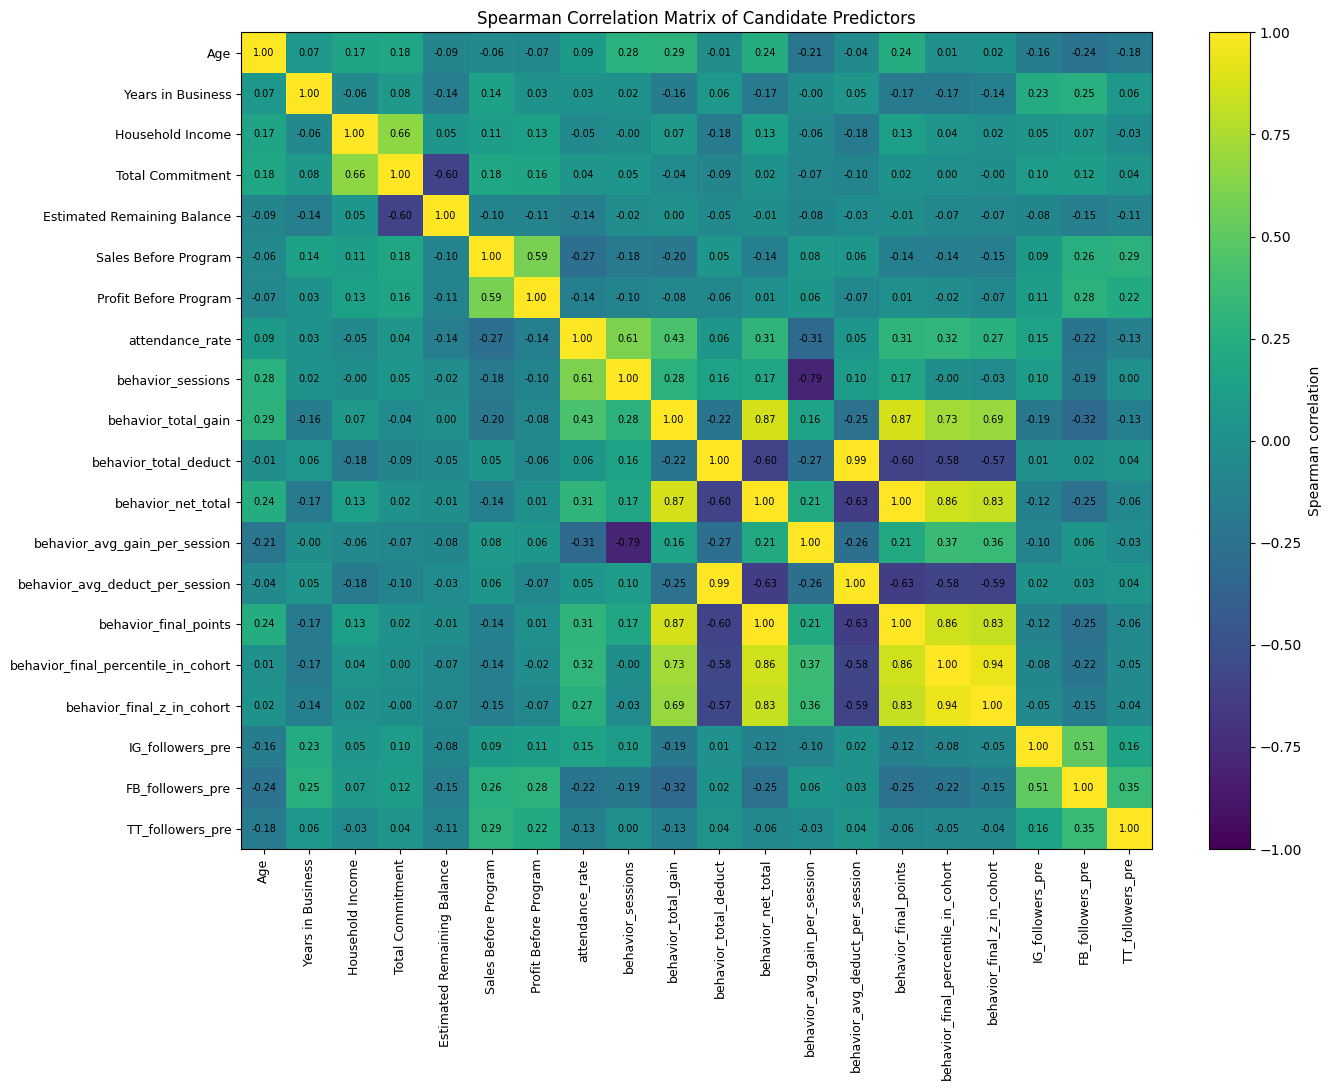

In [31]:
# 12.4.1 Predictor correlation heatmap

fig, ax = plt.subplots(figsize=(14, 11))

im = ax.imshow(
    predictor_corr,
    vmin=-1,
    vmax=1,
    aspect="auto"
)

ax.set_xticks(range(len(predictor_corr.columns)))
ax.set_xticklabels(
    predictor_corr.columns,
    rotation=90,
    fontsize=9
)

ax.set_yticks(range(len(predictor_corr.index)))
ax.set_yticklabels(
    predictor_corr.index,
    fontsize=9
)

for i in range(len(predictor_corr.index)):
    for j in range(len(predictor_corr.columns)):

        value = predictor_corr.iloc[i, j]

        if pd.notna(value):
            ax.text(
                j,
                i,
                f"{value:.2f}",
                ha="center",
                va="center",
                fontsize=7
            )

fig.colorbar(
    im,
    ax=ax,
    label="Spearman correlation"
)

ax.set_title(
    "Spearman Correlation Matrix of Candidate Predictors"
)

plt.tight_layout()
plt.show()

In [32]:
# 12.5 Redundant predictor screening

REDUNDANCY_THRESHOLD = 0.80

upper = np.triu(
    np.ones(predictor_corr.shape),
    k=1
).astype(bool)

redundancy_pairs = (
    predictor_corr
    .where(upper)
    .stack()
    .reset_index()
)

redundancy_pairs.columns = [
    "Variable 1",
    "Variable 2",
    "Spearman rho"
]

redundancy_pairs["Absolute rho"] = (
    redundancy_pairs["Spearman rho"].abs()
)

high_redundancy = (
    redundancy_pairs[
        redundancy_pairs["Absolute rho"] >= REDUNDANCY_THRESHOLD
    ]
    .sort_values(
        "Absolute rho",
        ascending=False
    )
)

if len(high_redundancy) == 0:
    print("No predictor pairs with |rho| >= 0.80")
else:
    display(high_redundancy)

,Variable 1,Variable 2,Spearman rho,Absolute rho
156,behavior_net_total,behavior_final_points,1.000000,1.000000
147,behavior_total_deduct,behavior_avg_deduct_per_session,0.993164,0.993164
180,behavior_final_percentile_in_cohort,behavior_final_z_in_cohort,0.942544,0.942544
136,behavior_total_gain,behavior_net_total,0.870862,0.870862
139,behavior_total_gain,behavior_final_points,0.870862,0.870862
157,behavior_net_total,behavior_final_percentile_in_cohort,0.856076,0.856076
175,behavior_final_points,behavior_final_percentile_in_cohort,0.856076,0.856076
158,behavior_net_total,behavior_final_z_in_cohort,0.825907,0.825907
176,behavior_final_points,behavior_final_z_in_cohort,0.825907,0.825907


In [33]:
# 12.6 Cramér's V function

def cramers_v(x, y):

    valid = pd.DataFrame({
        "x": x,
        "y": y
    }).dropna()

    if len(valid) == 0:
        return np.nan

    table = pd.crosstab(
        valid["x"],
        valid["y"]
    )

    if table.shape[0] < 2 or table.shape[1] < 2:
        return np.nan

    chi2 = chi2_contingency(
        table,
        correction=False
    )[0]

    n = table.values.sum()

    phi2 = chi2 / n

    r, k = table.shape

    phi2_corrected = max(
        0,
        phi2 - ((k - 1) * (r - 1)) / (n - 1)
    )

    r_corrected = (
        r - ((r - 1) ** 2) / (n - 1)
    )

    k_corrected = (
        k - ((k - 1) ** 2) / (n - 1)
    )

    denominator = min(
        k_corrected - 1,
        r_corrected - 1
    )

    if denominator <= 0:
        return np.nan

    return np.sqrt(
        phi2_corrected / denominator
    )

In [34]:
# 12.6.1 Add categorical variables

if "SSM Registered" in ssm.columns:

    ssm_temp = (
        ssm[
            ["Participant ID", "SSM Registered"]
        ]
        .drop_duplicates("Participant ID")
    )

    if "SSM Registered" not in relationship_base.columns:

        relationship_base = relationship_base.merge(
            ssm_temp,
            on="Participant ID",
            how="left"
        )


digital_columns = [
    "Participant ID",
    "IG_has_pre",
    "FB_has_pre",
    "TT_has_pre"
]

available_digital = [
    c for c in digital_columns
    if c in social.columns
]

social_cat = (
    social[available_digital]
    .drop_duplicates("Participant ID")
)

for c in social_cat.columns:

    if c == "Participant ID":
        continue

    if c not in relationship_base.columns:

        relationship_base = relationship_base.merge(
            social_cat[
                ["Participant ID", c]
            ],
            on="Participant ID",
            how="left"
        )

In [35]:
# 12.6.2 Select categorical variables

categorical_candidates = [
    "State",
    "Marital Status",
    "Education Level",
    "Working Status",
    "Industry/Business Sector",
    "Asnaf Status",

    "SSM Registered",

    "IG_has_pre",
    "FB_has_pre",
    "TT_has_pre",

    "behavior_grade_derived"
]

categorical_features = [
    c for c in categorical_candidates
    if c in relationship_base.columns
]

print("Categorical variables included:")

for c in categorical_features:
    print("-", c)

Categorical variables included:
- State
- Marital Status
- Education Level
- Working Status
- Industry/Business Sector
- Asnaf Status
- SSM Registered
- IG_has_pre
- FB_has_pre
- TT_has_pre
- behavior_grade_derived


In [36]:
# 12.6.3 Categorical association matrix

cramer_matrix = pd.DataFrame(
    np.eye(len(categorical_features)),
    index=categorical_features,
    columns=categorical_features
)

for i, col1 in enumerate(categorical_features):

    for j, col2 in enumerate(categorical_features):

        if i < j:

            value = cramers_v(
                relationship_base[col1],
                relationship_base[col2]
            )

            cramer_matrix.loc[col1, col2] = value
            cramer_matrix.loc[col2, col1] = value

display(cramer_matrix.round(2))

,State,Marital Status,Education Level,Working Status,Industry/Business Sector,Asnaf Status,SSM Registered,IG_has_pre,FB_has_pre,TT_has_pre,behavior_grade_derived
State,1.00,0.00,0.14,0.21,0.00,0.37,0.06,0.30,0.05,0.15,0.00
Marital Status,0.00,1.00,0.00,0.20,0.34,0.04,0.22,0.00,0.00,0.00,0.00
Education Level,0.14,0.00,1.00,0.22,0.00,0.24,0.20,0.00,0.17,0.22,0.16
Working Status,0.21,0.20,0.22,1.00,0.27,0.15,0.30,0.00,0.00,0.00,0.00
Industry/Business Sector,0.00,0.34,0.00,0.27,1.00,0.18,0.00,0.09,0.14,0.00,0.00
Asnaf Status,0.37,0.04,0.24,0.15,0.18,1.00,0.00,0.05,0.13,0.10,0.09
SSM Registered,0.06,0.22,0.20,0.30,0.00,0.00,1.00,0.00,0.03,0.11,0.00
IG_has_pre,0.30,0.00,0.00,0.00,0.09,0.05,0.00,1.00,0.46,0.36,0.11
FB_has_pre,0.05,0.00,0.17,0.00,0.14,0.13,0.03,0.46,1.00,0.41,0.00
TT_has_pre,0.15,0.00,0.22,0.00,0.00,0.10,0.11,0.36,0.41,1.00,0.00


In [37]:
# 12.6.4 Strong categorical associations

categorical_pairs = []

for i in range(len(categorical_features)):

    for j in range(
        i + 1,
        len(categorical_features)
    ):

        var1 = categorical_features[i]
        var2 = categorical_features[j]

        value = cramer_matrix.loc[
            var1,
            var2
        ]

        categorical_pairs.append({
            "Variable 1": var1,
            "Variable 2": var2,
            "Cramer's V": value
        })

categorical_pairs = pd.DataFrame(
    categorical_pairs
)

categorical_pairs = categorical_pairs.sort_values(
    "Cramer's V",
    ascending=False
)

display(categorical_pairs)

,Variable 1,Variable 2,Cramer's V
49,IG_has_pre,FB_has_pre,0.456602
52,FB_has_pre,TT_has_pre,0.413294
4,State,Asnaf Status,0.368453
50,IG_has_pre,TT_has_pre,0.360731
12,Marital Status,Industry/Business Sector,0.338233
29,Working Status,SSM Registered,0.304377
6,State,IG_has_pre,0.304291
27,Working Status,Industry/Business Sector,0.266920
21,Education Level,Asnaf Status,0.240028
19,Education Level,Working Status,0.223744


In [38]:
# 12.7 Detect Pre/Post pairs

def identify_pre_post(column_name):

    name = str(column_name).strip()
    lower = name.lower()

    is_pre = bool(
        re.search(
            r"\bpre\b|\(pre\)|pre[-_ ]",
            lower
        )
    )

    is_post = bool(
        re.search(
            r"\bpost\b|\(post\)|post[-_ ]",
            lower
        )
    )

    if not is_pre and not is_post:
        return None, None

    base = re.sub(
        r"\bpre\b|\bpost\b|\(pre\)|\(post\)|pre[-_ ]|post[-_ ]",
        "",
        lower
    )

    base = re.sub(
        r"[^a-z0-9]+",
        " ",
        base
    )

    base = re.sub(
        r"\s+",
        " ",
        base
    ).strip()

    if is_pre:
        return "pre", base

    if is_post:
        return "post", base

    return None, None


pair_dictionary = {}

for column in prepost.columns:

    period, base = identify_pre_post(
        column
    )

    if period is None:
        continue

    if base not in pair_dictionary:
        pair_dictionary[base] = {}

    pair_dictionary[base][period] = column


pre_post_pairs = []

for base, pair in pair_dictionary.items():

    if "pre" in pair and "post" in pair:

        pre_post_pairs.append({
            "Construct": base,
            "Pre Column": pair["pre"],
            "Post Column": pair["post"]
        })


pre_post_pairs = pd.DataFrame(
    pre_post_pairs
)

print(
    "Potential Pre/Post pairs detected:",
    len(pre_post_pairs)
)

display(pre_post_pairs)

Potential Pre/Post pairs detected: 67


,Construct,Pre Column,Post Column
0,able to identify 3 personal strengths and 3 we...,Pre - Able to identify 3 personal strengths a...,Post - Able to identify 3 personal strengths ...
1,have vision board,Pre - Have vision board,Post - Have vision board
2,your product label does it include the require...,Pre- Your product label — does it include the ...,Post - Your product label — does it include th...
3,have a standard operating procedure sop docume...,Pre - Have a Standard Operating Procedure (SOP...,Post - Have a Standard Operating Procedure (SO...
4,aware actual cost and selling price,Pre - Aware actual cost and selling price,Post - Aware actual cost and selling price
...,...,...,...
62,understand the main purpose of a business plan,Pre - Understand the main purpose of a Busines...,Post - Understand the main purpose of a Busine...
63,confident i can prepare a complete and convinc...,Pre - Confident I can prepare a complete and c...,Post - Confident I can prepare a complete and ...
64,confident speaking in front of audiences,Pre - Confident speaking in front of audiences,Post - Confident speaking in front of audiences
65,have presented your business or idea in front ...,Pre - Have presented your business or idea in ...,Post - Have presented your business or idea in...


In [39]:
# 12.8 Create competency delta variables

delta_data = prepost[
    ["Participant ID"]
].copy()

valid_delta_variables = []

for _, row in pre_post_pairs.iterrows():

    construct = row["Construct"]

    pre_col = row["Pre Column"]
    post_col = row["Post Column"]

    pre_numeric = pd.to_numeric(
        prepost[pre_col],
        errors="coerce"
    )

    post_numeric = pd.to_numeric(
        prepost[post_col],
        errors="coerce"
    )

    valid_pairs = (
        pre_numeric.notna()
        & post_numeric.notna()
    )

    if valid_pairs.sum() >= 20:

        safe_name = re.sub(
            r"[^a-z0-9]+",
            "_",
            construct.lower()
        ).strip("_")

        delta_name = f"delta_{safe_name}"

        delta_data[delta_name] = (
            post_numeric - pre_numeric
        )

        valid_delta_variables.append(
            delta_name
        )


# Merge delta_data into relationship_base
relationship_base = relationship_base.merge(
    delta_data,
    on="Participant ID",
    how="left"
)

print(
    "Numeric competency deltas created:",
    len(valid_delta_variables)
)

print(valid_delta_variables)

Numeric competency deltas created: 17
['delta_able_to_identify_3_personal_strengths_and_3_weaknesses', 'delta_confidence_level_in_your_leadership', 'delta_have_clear_vision_for_yourself_your_family_and_your_business_in_the_next_3_years', 'delta_well_know_who_target_customer', 'delta_know_the_pain_point_customer_face_that_makes_them_need_productsa', 'delta_i_am_confident_with_the_price_i_set', 'delta_confidence_level_in_pitching_your_business_idea_in_front_of_judges_or_a_large_audience', 'delta_level_of_courage_in_answering_spontaneous_questions_q_a_from_panel_members_or_investors', 'delta_comfortable_working_and_sharing_ideas_in_a_team', 'delta_confident_with_product_packaging_appearance', 'delta_confident_in_the_quality_of_the_photos_you_share_for_business', 'delta_confident_in_the_quality_of_the_videos_you_share_for_business', 'delta_confident_to_deliver_an_elevator_pitch', 'delta_confident_in_managing_businees_finance', 'delta_understand_the_main_purpose_of_a_business_plan', 'delta_

In [40]:
# 12.9 Behavior vs attendance

behavior_attendance_cols = [
    "attendance_rate",
    "behavior_total_gain",
    "behavior_total_deduct",
    "behavior_net_total",
    "behavior_avg_gain_per_session",
    "behavior_avg_deduct_per_session",
    "behavior_final_points",
    "behavior_final_z_in_cohort"
]

behavior_attendance_cols = [
    c for c in behavior_attendance_cols
    if c in relationship_base.columns
]

behavior_attendance_corr = (
    relationship_base[
        behavior_attendance_cols
    ]
    .corr(
        method="spearman",
        min_periods=20
    )
)

display(
    behavior_attendance_corr.round(3)
)

,attendance_rate,behavior_total_gain,behavior_total_deduct,behavior_net_total,behavior_avg_gain_per_session,behavior_avg_deduct_per_session,behavior_final_points,behavior_final_z_in_cohort
attendance_rate,1.000,0.425,0.060,0.308,-0.313,0.054,0.308,0.268
behavior_total_gain,0.425,1.000,-0.221,0.871,0.164,-0.255,0.871,0.691
behavior_total_deduct,0.060,-0.221,1.000,-0.601,-0.266,0.993,-0.601,-0.568
behavior_net_total,0.308,0.871,-0.601,1.000,0.214,-0.627,1.000,0.826
behavior_avg_gain_per_session,-0.313,0.164,-0.266,0.214,1.000,-0.263,0.214,0.356
behavior_avg_deduct_per_session,0.054,-0.255,0.993,-0.627,-0.263,1.000,-0.627,-0.587
behavior_final_points,0.308,0.871,-0.601,1.000,0.214,-0.627,1.000,0.826
behavior_final_z_in_cohort,0.268,0.691,-0.568,0.826,0.356,-0.587,0.826,1.000


In [41]:
# 12.9.1 Behavior vs attendance statistical test

temp = relationship_base[
    [
        "attendance_rate",
        "behavior_final_z_in_cohort"
    ]
].dropna()

if len(temp) >= 20:

    rho, p_value = spearmanr(
        temp["attendance_rate"],
        temp["behavior_final_z_in_cohort"]
    )

    print(f"Spearman rho: {rho:.3f}")
    print(f"p-value: {p_value:.4f}")
    print(f"Sample size: {len(temp)}")

else:

    print("Not enough observations.")

Spearman rho: 0.268
p-value: 0.0001
Sample size: 198


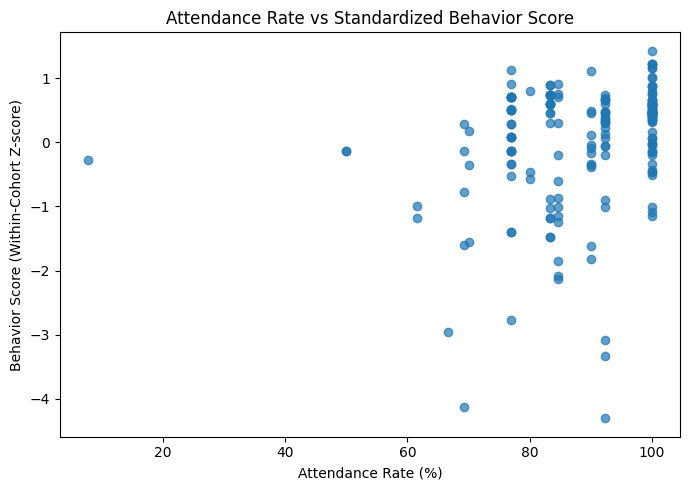

In [42]:
# 12.9.2 Behavior vs attendance plot

fig, ax = plt.subplots(figsize=(7, 5))

ax.scatter(
    temp["attendance_rate"],
    temp["behavior_final_z_in_cohort"],
    alpha=0.7
)

ax.set_title(
    "Attendance Rate vs Standardized Behavior Score"
)

ax.set_xlabel(
    "Attendance Rate (%)"
)

ax.set_ylabel(
    "Behavior Score (Within-Cohort Z-score)"
)

plt.tight_layout()
plt.show()

In [43]:
# 12.10 Behavior vs competency improvement

behavior_variables = [
    "behavior_total_gain",
    "behavior_total_deduct",
    "behavior_net_total",
    "behavior_avg_gain_per_session",
    "behavior_avg_deduct_per_session",
    "behavior_final_points",
    "behavior_final_z_in_cohort",
    "attendance_rate"
]

behavior_variables = [
    c for c in behavior_variables
    if c in relationship_base.columns
]

behavior_delta_results = []

for delta in valid_delta_variables:

    for behavior_var in behavior_variables:

        temp = relationship_base[
            [delta, behavior_var]
        ].dropna()

        if len(temp) < 20:
            continue

        rho, p = spearmanr(
            temp[delta],
            temp[behavior_var]
        )

        behavior_delta_results.append({
            "Competency Delta": delta,
            "Behavior Variable": behavior_var,
            "Spearman rho": rho,
            "Absolute rho": abs(rho),
            "p-value": p,
            "n": len(temp)
        })


behavior_delta_results = pd.DataFrame(
    behavior_delta_results
)

if len(behavior_delta_results):

    behavior_delta_results = (
        behavior_delta_results
        .sort_values(
            "Absolute rho",
            ascending=False
        )
    )

    display(
        behavior_delta_results.head(30)
    )

else:

    print(
        "No numeric competency relationships available."
    )

,Competency Delta,Behavior Variable,Spearman rho,Absolute rho,p-value,n
0,delta_able_to_identify_3_personal_strengths_an...,behavior_total_gain,0.568052,0.568052,0.001614,28
3,delta_able_to_identify_3_personal_strengths_an...,behavior_avg_gain_per_session,0.544480,0.544480,0.002739,28
15,delta_confidence_level_in_your_leadership,attendance_rate,0.499696,0.499696,0.001028,40
16,delta_have_clear_vision_for_yourself_your_fami...,behavior_total_gain,0.413669,0.413669,0.062308,21
19,delta_have_clear_vision_for_yourself_your_fami...,behavior_avg_gain_per_session,0.410862,0.410862,0.064286,21
6,delta_able_to_identify_3_personal_strengths_an...,behavior_final_z_in_cohort,0.408711,0.408711,0.030818,28
2,delta_able_to_identify_3_personal_strengths_an...,behavior_net_total,0.408711,0.408711,0.030818,28
5,delta_able_to_identify_3_personal_strengths_an...,behavior_final_points,0.408711,0.408711,0.030818,28
21,delta_have_clear_vision_for_yourself_your_fami...,behavior_final_points,0.398879,0.398879,0.073268,21
22,delta_have_clear_vision_for_yourself_your_fami...,behavior_final_z_in_cohort,0.398879,0.398879,0.073268,21


In [44]:
# 12.11 Baseline business vs competency improvement

baseline_business_variables = [
    "Sales Before Program",
    "Profit Before Program",
    "Years in Business",
    "Household Income",
    "Age"
]

baseline_business_variables = [
    c for c in baseline_business_variables
    if c in relationship_base.columns
]

baseline_delta_results = []

for baseline_var in baseline_business_variables:

    for delta in valid_delta_variables:

        temp = relationship_base[
            [baseline_var, delta]
        ].dropna()

        if len(temp) < 20:
            continue

        rho, p = spearmanr(
            temp[baseline_var],
            temp[delta]
        )

        baseline_delta_results.append({
            "Baseline Variable": baseline_var,
            "Competency Delta": delta,
            "Spearman rho": rho,
            "Absolute rho": abs(rho),
            "p-value": p,
            "n": len(temp)
        })


baseline_delta_results = pd.DataFrame(
    baseline_delta_results
)

if len(baseline_delta_results):

    baseline_delta_results = (
        baseline_delta_results
        .sort_values(
            "Absolute rho",
            ascending=False
        )
    )

    display(
        baseline_delta_results.head(30)
    )

else:

    print(
        "No baseline vs competency relationships available."
    )

/tmp/ipykernel_1117/3682065431.py:29: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, p = spearmanr(
/tmp/ipykernel_1117/3682065431.py:29: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, p = spearmanr(
/tmp/ipykernel_1117/3682065431.py:29: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, p = spearmanr(
/tmp/ipykernel_1117/3682065431.py:29: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, p = spearmanr(
/tmp/ipykernel_1117/3682065431.py:29: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, p = spearmanr(
/tmp/ipykernel_1117/3682065431.py:29: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, p = spearmanr(
/tmp/ipykernel_1117/3682065431.py:29: ConstantInputWarning: An input array i

,Baseline Variable,Competency Delta,Spearman rho,Absolute rho,p-value,n
16,Sales Before Program,delta_confident_speaking_in_front_of_audiences,-0.487180,0.487180,0.013511,25
27,Profit Before Program,delta_confident_in_the_quality_of_the_photos_y...,-0.416974,0.416974,0.038110,25
0,Sales Before Program,delta_able_to_identify_3_personal_strengths_an...,-0.395975,0.395975,0.040893,27
35,Years in Business,delta_confidence_level_in_your_leadership,-0.384046,0.384046,0.014424,40
49,Years in Business,delta_confident_i_can_prepare_a_complete_and_c...,-0.377524,0.377524,0.068953,24
14,Sales Before Program,delta_understand_the_main_purpose_of_a_busines...,-0.365159,0.365159,0.079331,24
55,Household Income,delta_know_the_pain_point_customer_face_that_m...,-0.347403,0.347403,0.088840,25
17,Profit Before Program,delta_able_to_identify_3_personal_strengths_an...,-0.319425,0.319425,0.104351,27
54,Household Income,delta_well_know_who_target_customer,-0.303127,0.303127,0.140763,25
47,Years in Business,delta_confident_in_managing_businees_finance,-0.287060,0.287060,0.146562,27


In [45]:
# 12.12 Check whether performance trajectory target exists

possible_target_columns = [
    "Performance Trajectory",
    "Trajectory",
    "trajectory",
    "trajectory_class",
    "Target",
    "target"
]

TARGET_COLUMN = next(
    (
        c for c in possible_target_columns
        if c in relationship_base.columns
    ),
    None
)

if TARGET_COLUMN is None:

    print(
        "Performance trajectory target has not been created yet."
    )

    print(
        "Validate the financial measurement period before creating High, Moderate and Low classes."
    )

else:

    print(
        "Target detected:",
        TARGET_COLUMN
    )

    display(
        relationship_base[
            TARGET_COLUMN
        ].value_counts(
            dropna=False
        )
    )

Performance trajectory target has not been created yet.
Validate the financial measurement period before creating High, Moderate and Low classes.


In [46]:
# 12.12.1 Numeric predictors vs performance trajectory

trajectory_numeric_results = []

if TARGET_COLUMN is not None:

    numeric_predictors_for_target = [
        c for c in predictor_numeric.columns
        if c in relationship_base.columns
    ]

    numeric_predictors_for_target += [
        c for c in valid_delta_variables
        if c in relationship_base.columns
    ]

    numeric_predictors_for_target = list(
        dict.fromkeys(
            numeric_predictors_for_target
        )
    )

    for variable in numeric_predictors_for_target:

        temp = relationship_base[
            [TARGET_COLUMN, variable]
        ].dropna()

        groups = [
            group[variable].values
            for _, group in temp.groupby(
                TARGET_COLUMN
            )
            if len(group) >= 5
        ]

        if len(groups) < 2:
            continue

        statistic, p = kruskal(
            *groups
        )

        medians = (
            temp
            .groupby(
                TARGET_COLUMN
            )[variable]
            .median()
            .to_dict()
        )

        trajectory_numeric_results.append({
            "Variable": variable,
            "Kruskal H": statistic,
            "p-value": p,
            "Group Medians": medians,
            "n": len(temp)
        })


    trajectory_numeric_results = pd.DataFrame(
        trajectory_numeric_results
    )

    if len(trajectory_numeric_results):

        trajectory_numeric_results = (
            trajectory_numeric_results
            .sort_values(
                "p-value"
            )
        )

        display(
            trajectory_numeric_results
        )

else:

    print(
        "Trajectory analysis skipped because target is not available yet."
    )

Trajectory analysis skipped because target is not available yet.


In [47]:
# 12.12.2 Categorical predictors vs performance trajectory

trajectory_categorical_results = []

if TARGET_COLUMN is not None:

    for variable in categorical_features:

        value = cramers_v(
            relationship_base[variable],
            relationship_base[TARGET_COLUMN]
        )

        table = pd.crosstab(
            relationship_base[variable],
            relationship_base[TARGET_COLUMN]
        )

        if table.shape[0] >= 2 and table.shape[1] >= 2:

            chi2, p, dof, expected = chi2_contingency(
                table
            )

        else:

            p = np.nan

        trajectory_categorical_results.append({
            "Variable": variable,
            "Cramer's V": value,
            "p-value": p
        })


    trajectory_categorical_results = pd.DataFrame(
        trajectory_categorical_results
    )

    trajectory_categorical_results = (
        trajectory_categorical_results
        .sort_values(
            "Cramer's V",
            ascending=False
        )
    )

    display(
        trajectory_categorical_results
    )

else:

    print(
        "Trajectory analysis skipped because target is not available yet."
    )

Trajectory analysis skipped because target is not available yet.


In [48]:
# 12.13 Section 12 summary

print("SECTION 12 SUMMARY")

print(
    "Numeric variables screened:",
    numeric_df.shape[1]
)

print(
    "Correlations with |rho| >= 0.30:",
    len(meaningful_correlations)
)

print(
    "Highly redundant predictor pairs:",
    len(high_redundancy)
)

print(
    "Categorical variables analysed:",
    len(categorical_features)
)

print(
    "Numeric competency deltas created:",
    len(valid_delta_variables)
)

if len(behavior_delta_results):
    print(
        "Behavior vs competency relationships tested:",
        len(behavior_delta_results)
    )

if len(baseline_delta_results):
    print(
        "Baseline vs competency relationships tested:",
        len(baseline_delta_results)
    )

if TARGET_COLUMN is None:
    print(
        "Performance trajectory analysis: Not run yet"
    )
else:
    print(
        "Performance trajectory target:",
        TARGET_COLUMN
    )

SECTION 12 SUMMARY
Numeric variables screened: 28
Correlations with |rho| >= 0.30: 48
Highly redundant predictor pairs: 9
Categorical variables analysed: 11
Numeric competency deltas created: 17
Behavior vs competency relationships tested: 136
Baseline vs competency relationships tested: 85
Performance trajectory analysis: Not run yet


# 13.0 Financial Outcome Availability by Cohort

In [49]:
# 13.0 Financial outcome availability by cohort

sales_columns = [
    "Sales Before Program",
    "Sales Month 1",
    "Sales Month 2",
    "Sales Month 3"
]

finance_target_audit = finance[
    [
        "Participant ID",
        "Cohort ID",
        "Funder/Program",
        "Year"
    ] + sales_columns
].copy()

for col in sales_columns:
    finance_target_audit[col] = pd.to_numeric(
        finance_target_audit[col],
        errors="coerce"
    )

finance_target_audit["Complete S0-S3"] = (
    finance_target_audit[sales_columns]
    .notna()
    .all(axis=1)
)

target_coverage = (
    finance_target_audit
    .groupby(
        ["Cohort ID", "Funder/Program", "Year"]
    )
    .agg(
        Participants=("Participant ID", "nunique"),
        Complete_S0_S3=("Complete S0-S3", "sum")
    )
    .reset_index()
)

target_coverage["Complete S0-S3 %"] = (
    target_coverage["Complete_S0_S3"]
    / target_coverage["Participants"]
    * 100
)

display(target_coverage)

,Cohort ID,Funder/Program,Year,Participants,Complete_S0_S3,Complete S0-S3 %
0,AIB-2026-MEKAR-C1,AIB,2026,28,26,92.857143
1,CIMB-2026-MH-C1,CIMB,2026,28,25,89.285714
2,MBSB-2025-C1,MBSB,2025,20,18,90.000000
3,MIB-2025-C1,MIB,2025,33,27,81.818182
4,MIB-2025-C2,MIB,2025,34,30,88.235294
5,MIB-2025-C3,MIB,2025,28,24,85.714286
6,UNDP-2026-C1,UNDP,2026,25,23,92.000000


In [50]:
# 13.1 Sales descriptive statistics by cohort

sales_summary = (
    finance_target_audit
    .groupby("Cohort ID")[sales_columns]
    .agg([
        "count",
        "mean",
        "median",
        "min",
        "max"
    ])
)

display(sales_summary)

Sales Before Program                                       \
                                 count         mean  median    min      max   
Cohort ID                                                                     
AIB-2026-MEKAR-C1                   28  2668.624643  1786.5  150.0  20000.0   
CIMB-2026-MH-C1                     27  3547.737037  1500.0    0.0  17000.0   
MBSB-2025-C1                        20  3075.700000  1550.0    0.0  14000.0   
MIB-2025-C1                         31  5766.322581  3500.0    5.0  24000.0   
MIB-2025-C2                         32  3332.031250  1725.0   20.0  20000.0   
MIB-2025-C3                         25  2171.360000  1200.0  200.0   9000.0   
UNDP-2026-C1                        25  3856.920000  2500.0  400.0  19500.0   

                  Sales Month 1                                       \
                          count         mean  median    min      max   
Cohort ID                                                              
AIB-2026-MEKAR-C1            27  3404.094815  2020.0  350.0  17560.0   
CIMB-2026-MH-C1              26  3672.269231  2350.0  100.0  20950.0   
MBSB-2025-C1                 18  4618.768889  2818.5  352.0  20600.0   
MIB-2025-C1                  27  8108.264815  6500.0  840.0  25087.0   
MIB-2025-C2                  32  4828.750000  2552.0  352.0  23037.0   
MIB-2025-C3                  28  3636.431429  2525.0   45.0   9600.0   
UNDP-2026-C1                 23  5718.347826  3950.0  500.0  21000.0   

                  Sales Month 2                                        \
                          count         mean   median    min      max   
Cohort ID                                                               
AIB-2026-MEKAR-C1            26  3895.570769  2375.00  336.0  20000.0   
CIMB-2026-MH-C1              27  3708.688889  1750.00    0.0  25350.0   
MBSB-2025-C1                 18  6154.098333  2522.29  340.0  30120.0   
MIB-2025-C1                  28  7459.078929  6575.00  450.0  22555.0   
MIB-2025-C2                  33  4874.642424  2800.00  300.0  21300.0   
MIB-2025-C3                  28  3602.350357  2675.50  155.0  11080.0   
UNDP-2026-C1                 23  5404.804783  3983.51  516.0  18000.0   

                  Sales Month 3                                         
                          count         mean   median     min      max  
Cohort ID                                                               
AIB-2026-MEKAR-C1            26  9779.144231  2625.00   192.0  76900.0  
CIMB-2026-MH-C1              27  3537.529630  2506.00     0.0  22950.0  
MBSB-2025-C1                 19  4989.000000  2300.00   234.0  19519.0  
MIB-2025-C1                  28  8569.626071  7670.00  1050.0  22142.0  
MIB-2025-C2                  33  5199.460606  3238.00   800.0  21900.0  
MIB-2025-C3                  27  4011.303704  3832.00   139.0  10600.0  
UNDP-2026-C1                 23  5641.176087  4181.05   516.0  16000.0

In [51]:
# 13.2 Financial tracking availability by cohort

sales_columns = [
    "Sales Before Program",
    "Sales Month 1",
    "Sales Month 2",
    "Sales Month 3"
]

tracking_availability = (
    finance
    .groupby("Cohort ID")
    .agg(
        Participants=("Participant ID", "nunique"),
        S0_Available=("Sales Before Program", lambda x: x.notna().sum()),
        S1_Available=("Sales Month 1", lambda x: x.notna().sum()),
        S2_Available=("Sales Month 2", lambda x: x.notna().sum()),
        S3_Available=("Sales Month 3", lambda x: x.notna().sum())
    )
    .reset_index()
)

display(tracking_availability)

,Cohort ID,Participants,S0_Available,S1_Available,S2_Available,S3_Available
0,AIB-2026-MEKAR-C1,28,28,27,26,26
1,CIMB-2026-MH-C1,28,27,26,27,27
2,MBSB-2025-C1,20,20,18,18,19
3,MIB-2025-C1,33,31,27,28,28
4,MIB-2025-C2,34,32,32,33,33
5,MIB-2025-C3,28,25,28,28,27
6,UNDP-2026-C1,25,25,23,23,23


In [52]:
# 13.2.1 Financial tracking completeness percentage

tracking_percentage = tracking_availability.copy()

for col in [
    "S0_Available",
    "S1_Available",
    "S2_Available",
    "S3_Available"
]:

    tracking_percentage[col] = (
        tracking_percentage[col]
        / tracking_percentage["Participants"]
        * 100
    ).round(1)

display(tracking_percentage)

,Cohort ID,Participants,S0_Available,S1_Available,S2_Available,S3_Available
0,AIB-2026-MEKAR-C1,28,100.0,96.4,92.9,92.9
1,CIMB-2026-MH-C1,28,96.4,92.9,96.4,96.4
2,MBSB-2025-C1,20,100.0,90.0,90.0,95.0
3,MIB-2025-C1,33,93.9,81.8,84.8,84.8
4,MIB-2025-C2,34,94.1,94.1,97.1,97.1
5,MIB-2025-C3,28,89.3,100.0,100.0,96.4
6,UNDP-2026-C1,25,100.0,92.0,92.0,92.0


# Saving the file

In [53]:
eda_base.to_csv(
    OUTPUT_DIR / "eda_base.csv",
    index=False
)

relationship_base.to_csv(
    OUTPUT_DIR / "relationship_base.csv",
    index=False
)

behavior_summary.to_csv(
    OUTPUT_DIR / "behavior_summary.csv",
    index=False
)